# <center>⚙️ Лекция 4. Классические алгоритмы и оценка качества моделей</center>
## <center>经典算法与模型质量评估</center>

### <center>Прикладные технологии искусственного интеллекта</center>
#### <center>Модуль 2 — Основы машинного обучения · 2 академических часа (90 минут)</center>

<div style='background-color: #E8F5E9; padding: 15px; border-left: 5px solid #2E7D32; margin: 20px 0;'>
<b>🎯 Цели лекции:</b><br>
1. объяснять принцип работы kNN, линейной и логистической регрессии, деревьев решений и k-means — «на пальцах» и по формулам;<br>2. выбирать алгоритм под задачу по таблице «данные / требуемая интерпретируемость / объём»;<br>3. строить и читать матрицу ошибок; считать accuracy, precision, recall, F1;<br>4. объяснять ловушку точности на несбалансированных данных;<br>5. читать ROC-кривую и понимать смысл AUC;<br>6. выбирать модель честно: кросс-валидация вместо подгонки под тест.
</div>

<div style='background-color: #FFF3E0; padding: 12px; border-left: 5px solid #FB8C00; margin: 20px 0;'>
<b>⏱️ План работы (90 минут):</b><br>
• Обзор пяти алгоритмов: у кого какие сильные стороны <i>(10 мин)</i><br>• kNN и параметр k <i>(10 мин)</i><br>• Линейная и логистическая регрессия <i>(15 мин)</i><br>• Деревья решений и k-means <i>(15 мин)</i><br>• Метрики классификации: матрица ошибок, P/R/F1, ROC <i>(25 мин)</i><br>• Метрики регрессии и кросс-валидация <i>(10 мин)</i><br>• Мини-тест и итоги <i>(5 мин)</i>
</div>

<div style='background-color: #E3F2FD; padding: 12px; border-left: 5px solid #1976D2; margin: 20px 0;'>
<b>📦 Что понадобится:</b> scikit-learn, matplotlib; встроенные датасеты sklearn.
</div>

<div style='background-color: #FCE4EC; padding: 12px; border-left: 5px solid #C2185B; margin: 20px 0;'>
<b>💡 Как работать с ноутбуком.</b> Теория читается сверху вниз; все рисунки уже внедрены в файл — внешние контейнеры и сетка не нужны. Демонстрационные ячейки с кодом можно запускать по порядку.
</div>


In [ ]:
# Настройка ноутбука: графики внутри документа, кириллица и иероглифы
%matplotlib inline
import numpy as np
import matplotlib.font_manager as fm
import os
for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf']:
    if os.path.exists(fp):
        fm.fontManager.addfont(fp)
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('Настройка завершена. Запускайте ячейки по порядку — сверху вниз.')

Настройка завершена. Запускайте ячейки по порядку — сверху вниз.


## 1. Пять классических алгоритмов: карта перед погружением

Все алгоритмы этой лекции — «классика» из 1960–1990-х. Они не модные, но до сих пор составляют **первые 80% любого табличного проекта**: быстрые, понятные, редко ломаются. Глубокое обучение (лекции 5–6) подключают, когда данные — картинки, звук или текст.

| Алгоритм | Тип | Идея в одну строку | Сильная сторона | Слабая |
|---|---|---|---|---|
| **kNN** | классификация/регрессия | скажи мне, кто твои соседи | простота, без обучения | медленный на новых данных; чуток к масштабу |
| **Линейная регрессия** | регрессия | прямая линия через облако точек | интерпретируемость, скорость | только линейные связи |
| **Логистическая регрессия** | классификация | линия + сигмоида = вероятность | вероятности, интерпретация весов | тоже линейная граница |
| **Дерево решений** | оба | серия вопросов «если… то…» | читаемая инструкция, любые признаки | легко переобучается без ограничения глубины |
| **k-means** | кластеризация (без учителя) | перекрась точки — сдвинь центры | быстрый способ найти группы | число k задают заранее; только «круглые» кластеры |

Правило выбора для курсового проекта с таблицей: **начинайте с логистической регрессии или дерева** — это «базовые линии» (baseline). Любая сложная модель обязана их побеждать, иначе она не нужна.


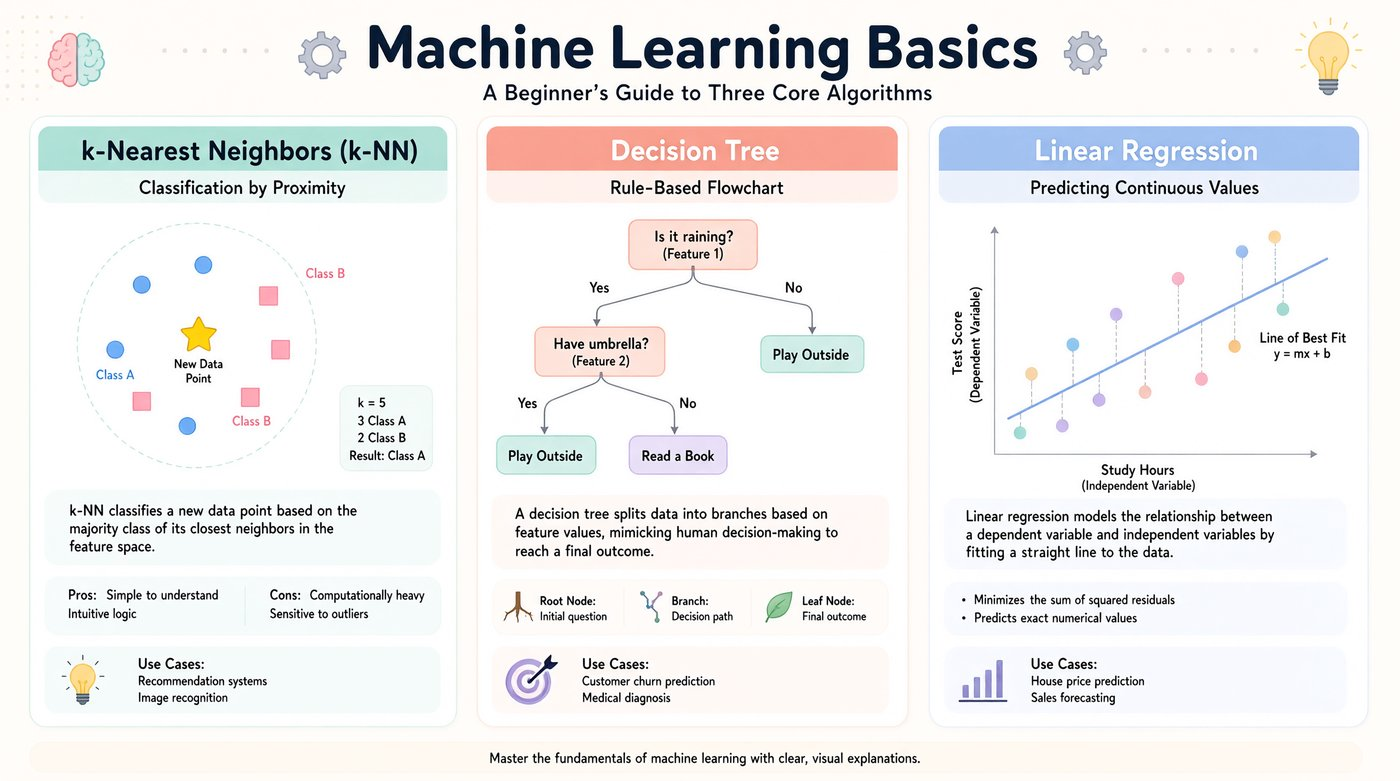
Рис. 1. Визуализация трёх базовых алгоритмов: k-ближайших соседей, решающее дерево и линейная регрессия.

### 🏘️ 1. Метод k ближайших соседей (k-Nearest Neighbors, k-近邻, kNN)
**Идея:** «Скажи, кто твои соседи, и я скажу, кто ты».  
Когда приходит новый объект, алгоритм находит `k` самых похожих объектов из обучающей выборки.
- **Плюсы:** Очень просто и интуитивно понятно.
- **Минусы:** Медленно работает на больших данных, чувствителен к масштабу признаков.

### 🌳 2. Решающее дерево (Decision Tree, 决策树)
**Идея:** Цепочка вопросов «да / нет», как в игре «Угадай, кто я?».
```
Часов подготовки > 5?
+-- Да --> Посещаемость > 70%?
|   +-- Да --> Сдал (1)
|   +-- Нет --> Не сдал (0)
+-- Нет --> Не сдал (0)
```
- **Плюсы:** Легко интерпретировать, можно нарисовать на бумаге.
- **Минусы:** Склонно к переобучению, если дерево слишком глубокое.

### 📈 3. Линейная регрессия (Linear Regression, 线性回归)
**Идея:** Провести прямую линию через облако точек так, чтобы сумма ошибок была минимальной.  
Формула: `Цена = a * Площадь + b`. Компьютер подбирает числа `a` и `b` автоматически.
- **Плюсы:** Быстро, просто, хорошо работает для линейных зависимостей.
- **Минусы:** Не может уловить сложные, нелинейные закономерности.

## 2. Алгоритм kNN (k Nearest Neighbors): скажи мне, кто твои соседи
Один из самых простых и понятных алгоритмов классификации.

В лекции 3 мы уже встретили идею. Теперь — детали, которые решают всё.
### Принцип:
1. Берём новый объект (красный вопросительный знак).
2. Находим **k** ближайших к нему объектов из обучающей выборки.
3. Смотрим, каких классов эти соседи.
4. Присваиваем новому объекту тот класс, которого среди соседей больше (**голосование большинства**).

**Обучение** kNN ленивое: просто запомнить все примеры (таблицу train). **Предсказание:** найти $k$ ближайших соседей нового объекта и взять голосование:

$$\hat{y} = \text{режим}\{y_1, \dots, y_k\} \quad \text{(класс, } \hat{y} = \frac{1}{k}\sum y_i \text{ для регрессии)}$$

Параметр $k$ — главный регулятор гладкости:


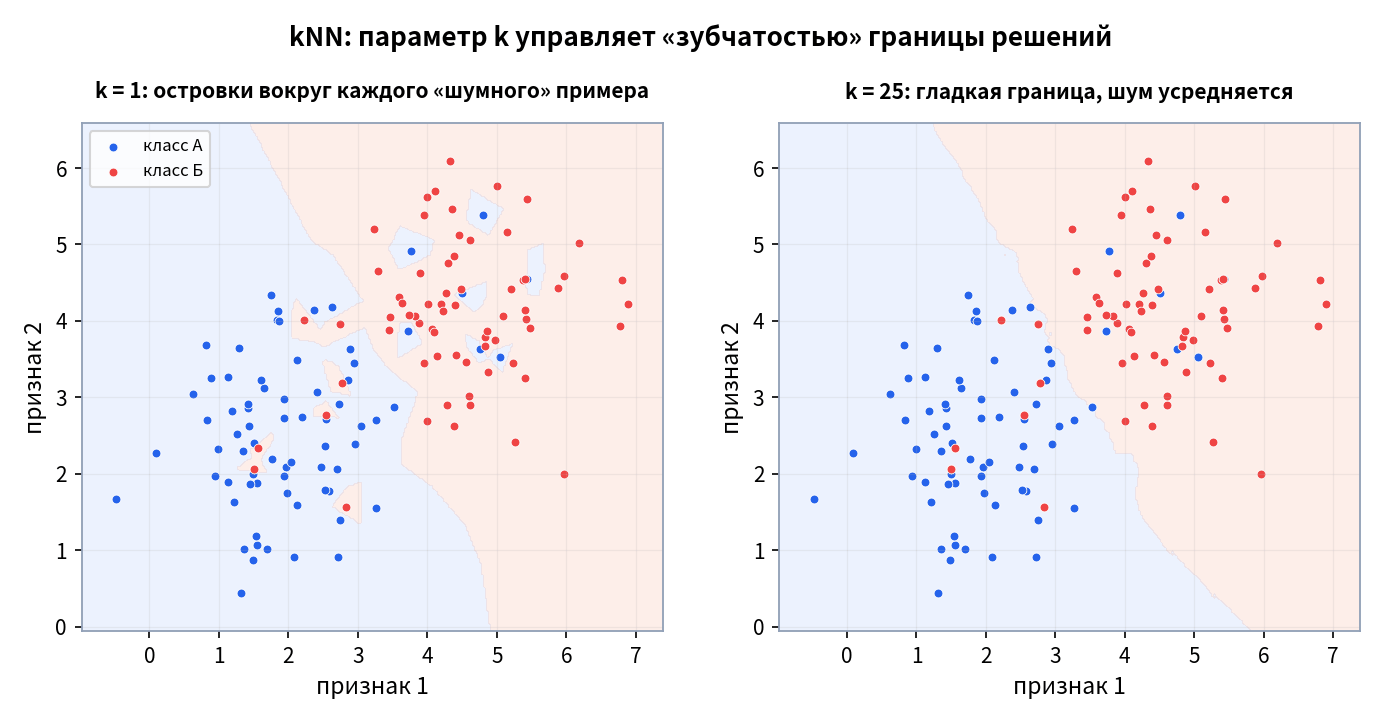

- $k = 1$: граница обвивает каждый пример, включая «шумные» точки с ошибочной меткой → переобучение;
- большой $k$: граница гладкая, но детали размываются → недообучение;
- практика: $k$ подбирают кросс-валидацией (чётные, обычно 3–15); $k$ берут **нечётным**, чтобы голосование не зависало при равенстве.

Две обязательные гигиенические меры: (1) **нормировка признаков** (`StandardScaler`) — иначе «доход в юанях» задавит «рост в метрах» из лекции 2; (2) при несбалансированных классах — **взвешивание** соседей по расстоянию (`weights='distance'`), чтобы толпа далёких примеров мажоритарного класса не топила редкий.


Предсказание: Мужчина


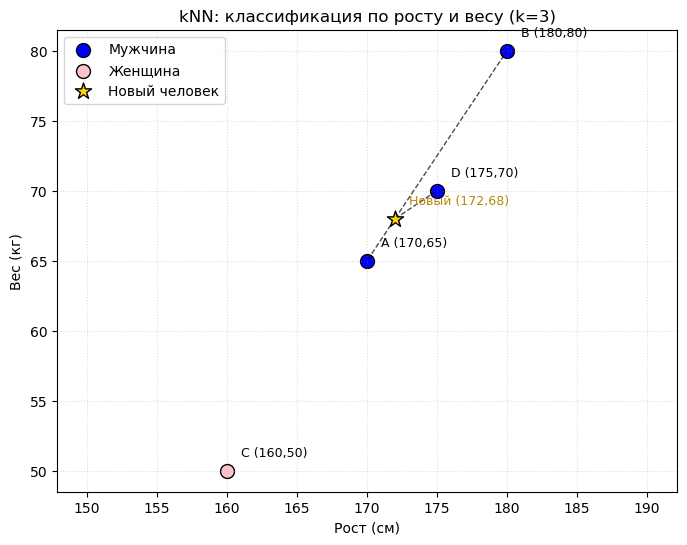

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import pairwise_distances

# Данные: [рост, вес]
X_train = np.array([[170, 65],
                    [180, 80],
                    [160, 50],
                    [175, 70]])
y_train = np.array(['Мужчина', 'Мужчина', 'Женщина', 'Мужчина'])

# Создаём и обучаем модель kNN с k=3
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Новый человек
new_person = np.array([[172, 68]])
prediction = knn.predict(new_person)
print("Предсказание:", prediction[0])

# Находим 3 ближайших соседа
distances, indices = knn.kneighbors(new_person, n_neighbors=3)
neighbors = X_train[indices[0]]

# Визуализация
plt.figure(figsize=(8, 6))

# Отрисовка обучающих точек
for i, (x, y, label) in enumerate(zip(X_train[:, 0], X_train[:, 1], y_train)):
    color = 'blue' if label == 'Мужчина' else 'pink'
    plt.scatter(x, y, c=color, s=100, edgecolors='black', label=label if i == 0 or i == 2 else "")

# Точка нового человека
plt.scatter(new_person[0, 0], new_person[0, 1], c='gold', s=150, marker='*', edgecolors='black', zorder=5, label='Новый человек')

# Линии к 3 ближайшим соседям
for neighbor in neighbors:
    plt.plot([new_person[0, 0], neighbor[0]],
             [new_person[0, 1], neighbor[1]],
             'k--', linewidth=1, alpha=0.7)

# Подписи точек
labels = ['A (170,65)', 'B (180,80)', 'C (160,50)', 'D (175,70)']
for i, (x, y) in enumerate(X_train):
    plt.text(x + 1, y + 1, labels[i], fontsize=9)

plt.text(new_person[0, 0] + 1, new_person[0, 1] + 1, 'Новый (172,68)', fontsize=9, color='darkgoldenrod')

plt.xlabel('Рост (см)')
plt.ylabel('Вес (кг)')
plt.title('kNN: классификация по росту и весу (k=3)')
plt.grid(True, linestyle=':', alpha=0.4)
plt.legend(loc='upper left')
plt.axis('equal')
plt.show()


> 🗣️ **Китайская поговорка «近朱者赤，近墨者黑»** — «с красным станешь красным, с чёрным — чёрным» — описывает KNN точнее любого учебника: **класс объекта определяется его окружением.** Запомните её — на семинаре и зачёте она часто оказывается самым коротким и точным ответом.


## 3. Линейная регрессия и её вероятностный брат
Cамый базовый алгоритм для предсказания чисел

### 3.1. Линейная регрессия: цена квартиры за один умножитель

Модель — прямая: $\hat{y} = w_1 x_1 + w_2 x_2 + \dots + b$.

Для одной переменной это знакомая $y = wx + b$.


### Формула:
$$y = w \cdot x + b$$

- $x$ — признак (например, площадь квартиры)
- $y$ — цель (цена)
- $w$ (weight) — вес, насколько сильно признак влияет на цену
- $b$ (bias) — смещение, базовая цена

Задача модели — подобрать такие $w$ и $b$, чтобы линия прошла **как можно ближе** ко всем точкам данных.

# 📉 Что такое ошибка (Loss)?

Ошибка — это расстояние от реальной точки до линии предсказания.

Мы используем **MSE (Mean Squared Error)** — средний квадрат ошибки:
$$MSE = \frac{1}{N} \sum (y_{real} - y_{pred})^2$$

Чем меньше MSE, тем лучше модель.

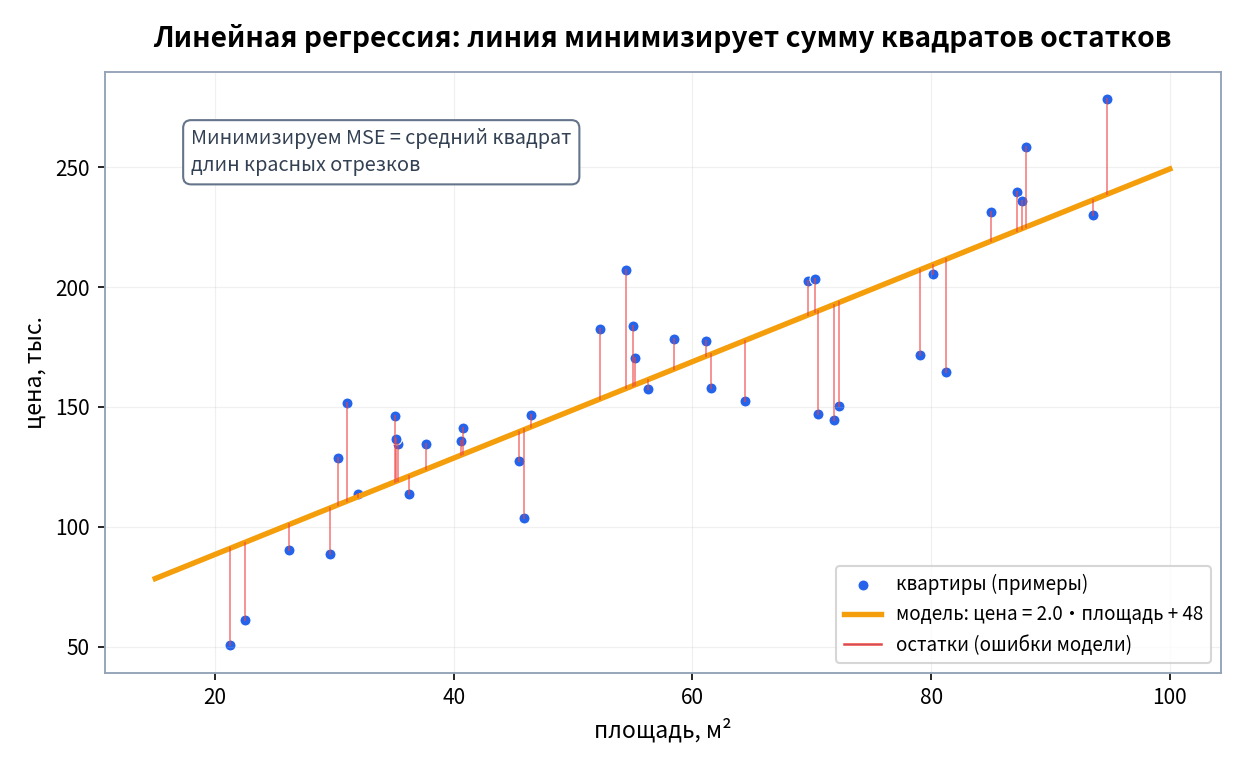

Обучение = найти веса, минимизирующие **среднеквадратичную ошибку**:

$$\text{MSE} = \frac{1}{n} \sum_i (y_i - \hat{y}_i)^2 \to \min_{w, b}$$

У задачи есть точное решение в один матричный ход ($w = (X^TX)^{-1}X^Ty$ — «метод наименьших квадратов», ему 220 лет!). Веса читаются как **цены признаков**: «+1 м² → +2,1 тыс.» — модели такого рода обязаны быть в отчётах бизнесу именно за объяснимость.

Два предостережения: MSE жёстко наказывает **выбросы** (квадрат ошибки) — если в данных есть «дворцы», смотрят также MAE; и линейность — не приговор: признак «площадь²» или «log(доход)» часто возвращает линейную модель к жизни.



### 🎓 Аналогия: регрессия как «рубрика оценивания эссе»

Преподаватель проверяет эссе по рубрике с весами: «орфография — 20 %, логика — 50 %, оригинальность — 30 %». Меняя веса, преподаватель меняет итоговую оценку. Линейная регрессия делает то же самое, только **веса подбираются автоматически из данных**, а не назначаются вручную. Отсюда главное преимущество метода — **интерпретируемость**: модель не только предсказывает, но и объясняет, что и насколько повлияло на ответ.


### 3.2. Логистическая регрессия: та же линия, но вероятность

А если ответ — «сдал/не сдал»? Прогоним линию через **сигмоиду** $\sigma(z) = \frac{1}{1+e^{-z}}$:

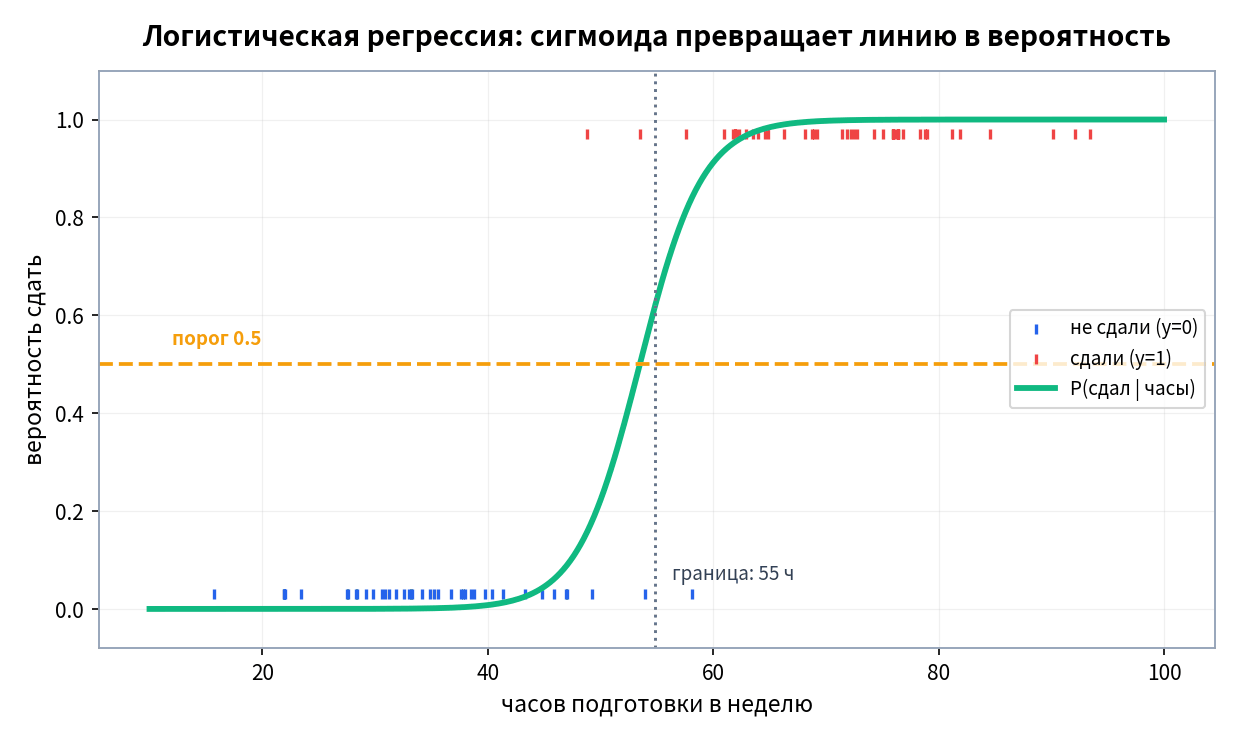

$$P(y=1 \mid x) = \sigma(w_1 x_1 + \dots + b) \in (0, 1)$$

Модель выдаёт **вероятность**; решение принимает порог (по умолчанию 0.5, но его двигают: для диагностики порог снижают, чтобы не пропускать больных — см. §5 про precision/recall). Логистическая регрессия — не «регрессия для классификации по недоразумению», а честная статистическая модель: её веса отвечают на вопрос «как изменится шанс при +1 к признаку». Это делает её самой любимой базовой линией в медицине и кредитном скоринге.


---
## 🎬 Видеоматериалы: kNN, регрессии и метрики
Видео к разделам 2–3 и метрикам: kNN, регрессии, матрица ошибок, ROC/AUC.
### 🇷🇺 РУС · русскоязычные видео (2)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [ML #29. Метрические методы: k ближайших соседей (kNN)](https://rutube.ru/video/40b38cd959a0b4627a67bfe0c96992df/) | Rutube · SelfEdu | 11 мин | Л4 §2: kNN (П3 — классификация ирисов)  X |
| 2 | [ML #13. Логистическая регрессия](https://rutube.ru/video/7c5d902ce44b722b90c09e70a8f4e744/) | Rutube · SelfEdu | 11 мин | Л4 §3.2: логистическая регрессия  X |
### 🇨🇳 中文 · китайскоязычные видео (оригинал в курсиве) (5)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [Линейные модели](https://www.bilibili.com/video/BV1Y7411d7Ys?p=2)<br>· ориг.: *2.线性模型* | Bilibili · 刘二大人 | 43 мин | Л4 §3.1: линейная регрессия с нуля  ✓ |
| 2 | [Логистическая регрессия](https://www.bilibili.com/video/BV1Y7411d7Ys?p=6)<br>· ориг.: *6.逻辑斯蒂回归* | Bilibili · 刘二大人 | 44 мин | Л4 §3.2 / П3: классификация на вероятностях  ✓ |
| 3 | [Линейная регрессия](https://www.bilibili.com/video/BV1EY6FBwE8P?p=19)<br>· ориг.: *19.1-线性回归* | Bilibili · 李沐 | 14 мин | Л4 §3.1: функция потерь и оптимизация  ✓ |
| 4 | [Разделение данных и матрица ошибок](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=30)<br>· ориг.: *6-2 数据分离与混淆矩阵* | Bilibili · 清华AI | 21 мин | Л4 §5: выборки и метрики  ✓ |
| 5 | [Линейная регрессия с нуля](https://www.bilibili.com/video/BV1EY6FBwE8P?p=21)<br>· ориг.: *21.3-线性回归的从零开始实现-* | Bilibili · 李沐 | 15 мин | Л4 §2: реализация линейной регрессии  ✓ |
### 🇬🇧 EN · англоязычные видео (4)
| № | Видео | Источник | Длит. | Раздел лекции  | Доступность |
|---|-------|----------|-------|----------------|---|
| 1 | [StatQuest: матрица ошибок (confusion matrix)](https://www.bilibili.com/video/BV1nC411H7wZ/)<br>· ориг.: *【官方双语】一个视频理解混淆矩阵！confusion matrix* | Bilibili · StatQuest | 7 мин | Л4: матрица ошибок  ✓ |
| 2 | [StatQuest: ROC и AUC — подробное объяснение](https://www.bilibili.com/video/BV1Fw4m1i72L/)<br>· ориг.: *【官方双语】ROC & AUC 详细解释！* | Bilibili · StatQuest | 16 мин | Л4: ROC-кривая и AUC  ✓ |
| 3 | [StatQuest: логистическая регрессия — основные идеи](https://www.bilibili.com/video/BV1Q2QDYNEBN/)<br>· ориг.: *【官方双语】一个视频带你看懂逻辑回归！* | Bilibili · StatQuest | 8 мин | Л4 §2: логистическая регрессия и сигмоида  ✓ |
| 4 | [Andrew Ng: Функция потерь и её интуиция](https://www.bilibili.com/video/BV1owrpYKEtP?p=7)<br>· ориг.: *7.成本函数及其直觉 (речь — английская)* | Bilibili · 吴恩达 | 23 мин | Л4 §3: что минимизирует модель  ✓ |

> 📄 Полная версия с идентичными ссылками: PDF «Видеоматериалы по 5 модулям и 10 лекциям», глава соответствующего модуля.

## 4. Деревья и кластеры

### 4.1. Дерево решений: инструкция, которую можно распечатать


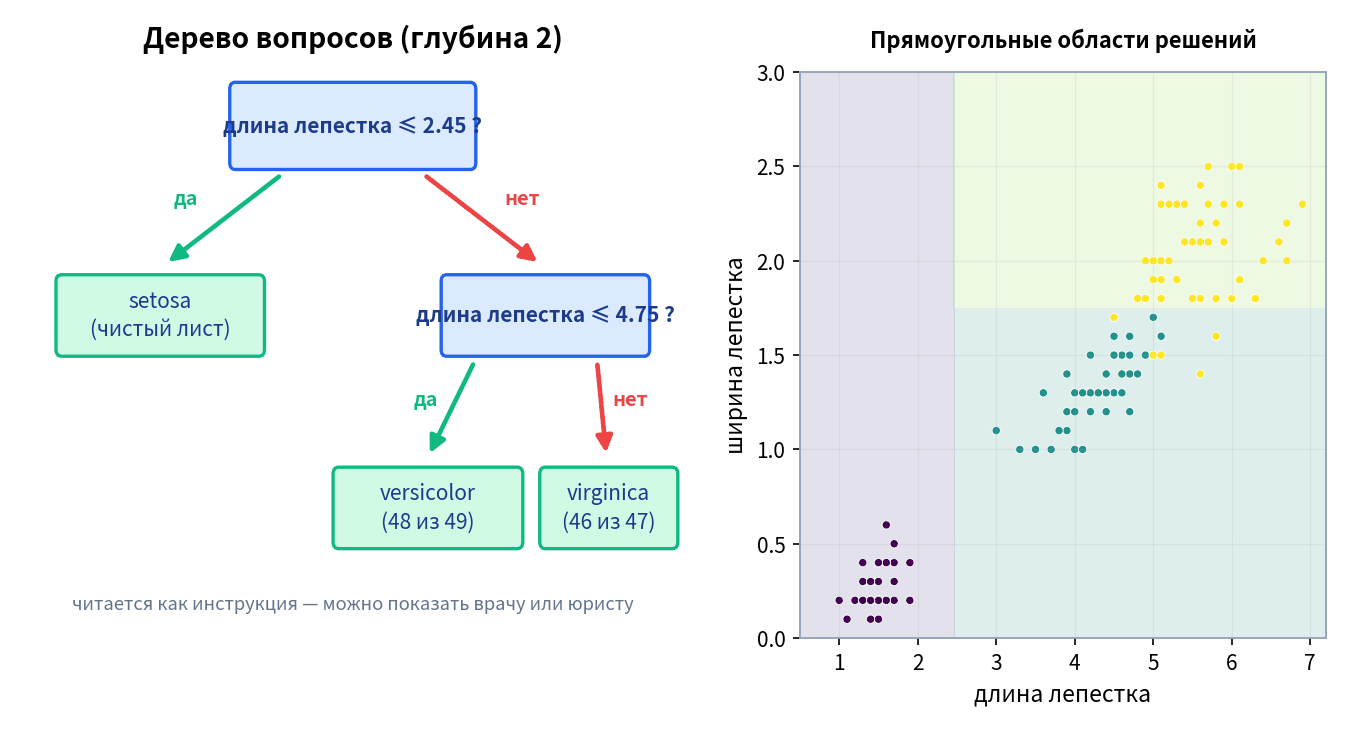

Дерево строит цепочку порогов: «длина лепестка ≤ 2.45?» — и каждый лист объявляет класс. Обучение жадное: на каждом шаге выбирается вопрос, который **чище всего делит** примеры (критерий Джини или энтропия). Для ирисов хватает глубины 2 — и это читаемая инструкция из двух вопросов.

Сильные стороны: работает с любыми типами признаков, не требует нормировки, легко рисуется. Слабость: **деревья без ограничений запоминают всю таблицу** (глубина 10+ = переобучение). Лечится ограничением глубины (`max_depth`), минимумом примеров в листе — или ансамблем из многих деревьев (Random Forest, градиентный бустинг — за рамками курса, но упомянем на практике).

### 4.2. k-means: группы без меток


## 4. Обучение без учителя: Кластеризация (无监督学习：聚类)

До сих пор мы говорили об **обучении с учителем (Supervised Learning, 监督学习)**, где у нас есть правильные ответы (метки). Но что, если правильных ответов нет?

**Обучение без учителя (Unsupervised Learning, 无监督学习)** ищет скрытые структуры в данных самостоятельно. Самый популярный метод — **кластеризация (Clustering, 聚类)**.

**Кластеризация** разбивает объекты на группы (кластеры) так, чтобы объекты внутри одной группы были максимально похожи друг на друга, а объекты из разных групп — отличались.

### 🎯 Алгоритм K-means (K-средних, K均值算法)
1. Выбрать количество кластеров **K** (например, K=3).
2. Случайно разместить **K** центров (центроидов).
3. Отнести каждую точку к **ближайшему** центру.
4. Сдвинуть каждый центр в **середину** (среднее арифметическое) своей новой группы.
5. Повторять шаги 3–4, пока центры не перестанут двигаться.


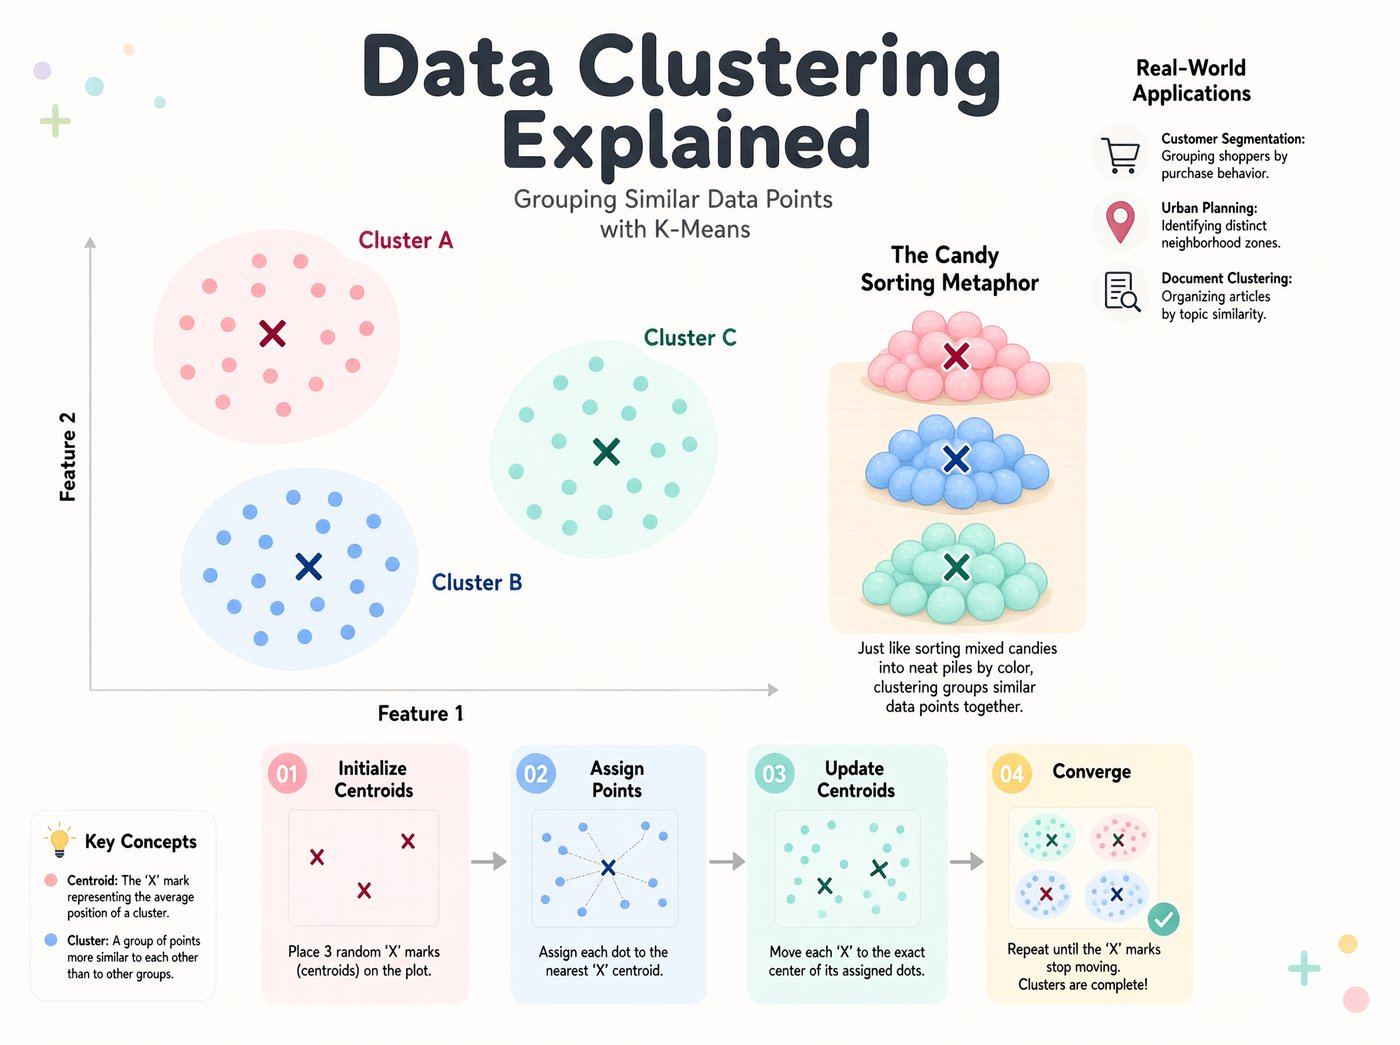

*Рис. 4. Визуализация K-means: разнородные точки группируются в 3 чётких кластера с центрами (X).*

**Где в жизни:** сегментация клиентов маркетплейса, сжатие палитры изображений, группировка новостных тем.

> 🛍️ **Пример из жизни:** Интернет-магазин не знает заранее, какие типы покупателей существуют. Алгоритм K-means может автоматически выделить 3 группы:
> 1. "Активные" (тратят много, заходят часто).
> 2. "Редкие" (тратят мало, заходят редко).
> 3. "Присматривающиеся" (заходят часто, но покупают по одному дешёвому товару).

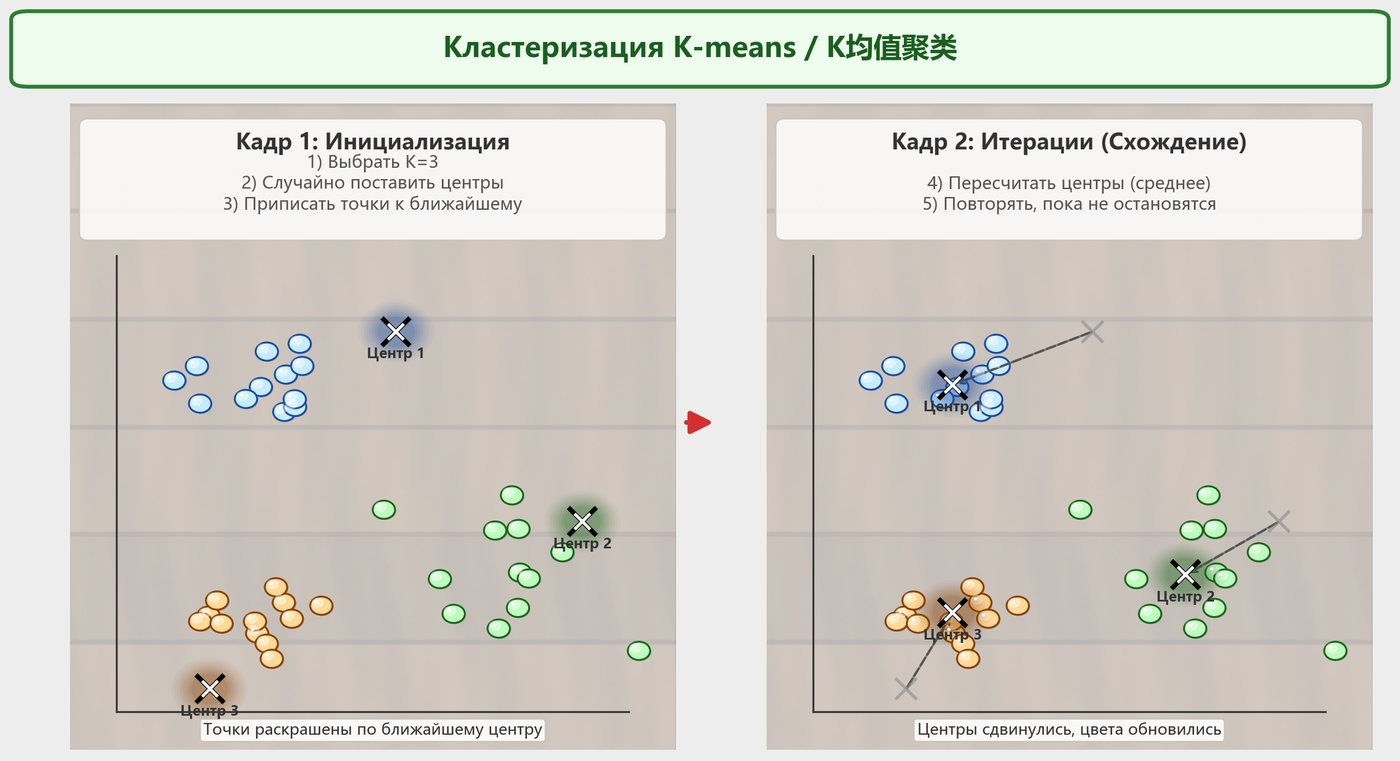

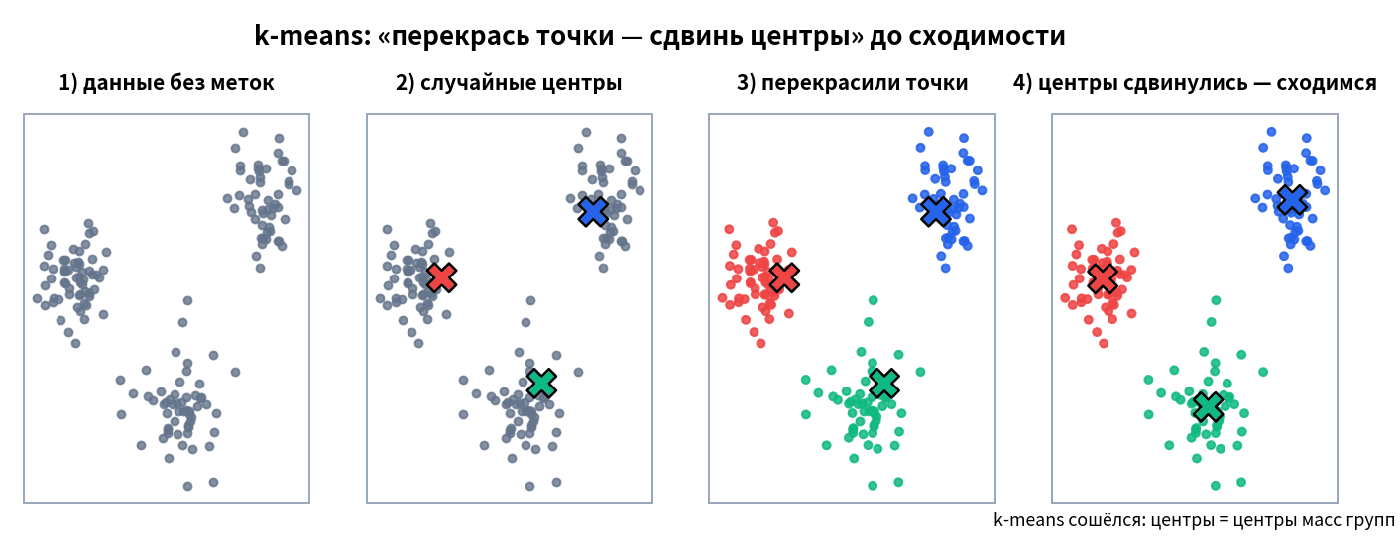

Алгоритм из двух чередующихся шагов: (1) каждая точка приписывается к **ближайшему центру**; (2) каждый центр переезжает в **среднее** своих точек. Повторять до сходимости. Важно понимать ограничения:

- число кластеров $k$ задаётся заранее; его выбирают «методом локтя» (строим инерцию — сумму расстояний до центров — для $k=1..10$ и ищем излом);
- k-means любит «круглые» кластеры близкого размера; кольца и полумесяцы разбивает плохо;
- результат зависит от стартовых центров → запускать несколько раз (`n_init=10`).




C:\Work\ai_course\env_ai\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Метки кластеров: [1 1 1 0 0 0 2 2 2]
Центры кластеров:
 [[ 5.7  2. ]
 [50.  20. ]
 [21.  13.7]]


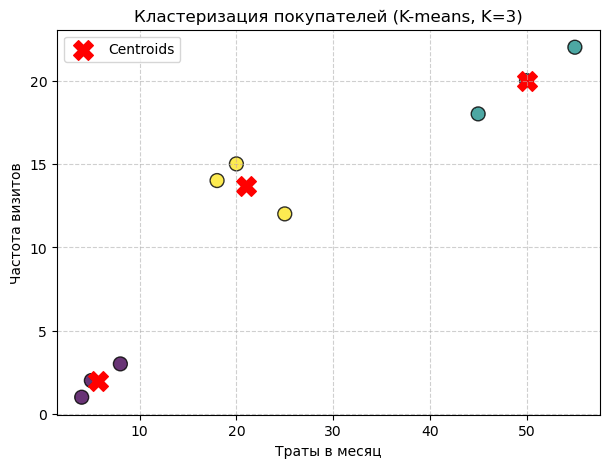

In [ ]:
# Демонстрация кластеризации K-means
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Синтетические данные о покупателях
customers = np.array([
    [50, 20], [45, 18], [55, 22],
    [5, 2], [8, 3], [4, 1],
    [20, 15], [25, 12], [18, 14]
])

# Просто убираем n_jobs — в новых версиях он не нужен
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(customers)

print("Метки кластеров:", labels)
print("Центры кластеров:\n", np.round(kmeans.cluster_centers_, 1))

# Визуализация
plt.figure(figsize=(7, 5))
plt.scatter(customers[:, 0], customers[:, 1], c=labels, cmap='viridis', s=100, alpha=0.8, edgecolors='black')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Траты в месяц')
plt.ylabel('Частота визитов')
plt.title('Кластеризация покупателей (K-means, K=3)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 5. Метрики классификации: где решается судьба моделей

### 5.1. Матрица ошибок — бухгалтерия предсказаний

Accuracy «верных ответов» не различает **типы** ошибок. А цена ошибок разная: пропустить болезнь (FN) и ругнуть здорового (FP) — несимметричные катастрофы. Сначала наведём бухгалтерию:


Кажется, что **Точность (Accuracy, 准确率)** — лучшая метрика. Но это не так!

# 📊 Accuracy (Точность)

**Смысл:** доля всех правильных предсказаний модели среди всех примеров.  
**Когда используют:** когда классы сбалансированы и все ошибки одинаково важны.  
**Осторожно:** в задачах с дисбалансом (например, редкая болезнь) Accuracy может выглядеть отлично, хотя модель почти ничего не предсказывает правильно по важному классу.

## Формула

$$
\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}
$$

---

## Расшифровка

| Сокращение | Название | Описание |
| :--- | :--- | :--- |
| **TP** | True Positive | Верно предсказанные положительные случаи (болен → «болен») |
| **TN** | True Negative | Верно предсказанные отрицательные случаи (здоров → «здоров») |
| **FP** | False Positive | Ложноположительные (здоров → ошибочно «болен») |
| **FN** | False Negative | Ложноотрицательные (болен → ошибочно «здоров») |


| | Предсказано: БОЛЕН (1) | Предсказано: ЗДОРОВ (0) |
|---|---|---|
| **Реально: БОЛЕН (1)** | True Positive (TP) <br>*(Верно: нашли болезнь)* | False Negative (FN) <br>*(Ошибка: пропустили болезнь)* |
| **Реально: ЗДОРОВ (0)** | False Positive (FP) <br>*(Ошибка: ложная тревога)* | True Negative (TN) <br>*(Верно: подтвердили здоровье)* |
---
### 🦠 Пример: Тест на редкую болезнь
В городе 100 человек. **1 человек болен**, 99 здоровы.  
Ленивая модель говорит: *«Все здоровы!»* (всегда предсказывает 0).

## Пример (редкая болезнь: 1 больной, 99 здоровых)

Модель предсказывает всем «здоров». Тогда:
- TP = 0
- TN = 99
- FP = 0
- FN = 1

Подставляем в формулу:

$$
\text{Accuracy} = \frac{0 + 99}{0 + 99 + 0 + 1} = \frac{99}{100} = 0.99 = 99\%
$$
- **Accuracy (Точность):** 99% (99 из 100 угадано верно). Звучит отлично!
- **Реальность:** Модель бесполезна, она не нашла ни одного больного.
При этом модель не нашла ни одного больного — вот почему в таких задачах Accuracy вводит в заблуждение.

  
Поэтому нам нужны другие метрики, основанные на **Матрице ошибок (Confusion Matrix, 混淆矩阵)**:


### 📐 Ключевые метрики:
1. **Precision (Точность предсказания, 精确率):** Из всех, кого модель назвала больными, сколько реально больны?  
   `Precision = TP / (TP + FP)`
2. **Recall (Полнота, 召回率):** Из всех реально больных, сколько модель смогла найти?  
   `Recall = TP / (TP + FN)`

>  **Правило:** Если цена ошибки высока (пропуск болезни, пропуск дефекта на заводе), мы максимизируем **Recall (召回率)**. Если цена ложной тревоги высока (отправка спама в важный рабочий email), мы максимизируем **Precision**.



---




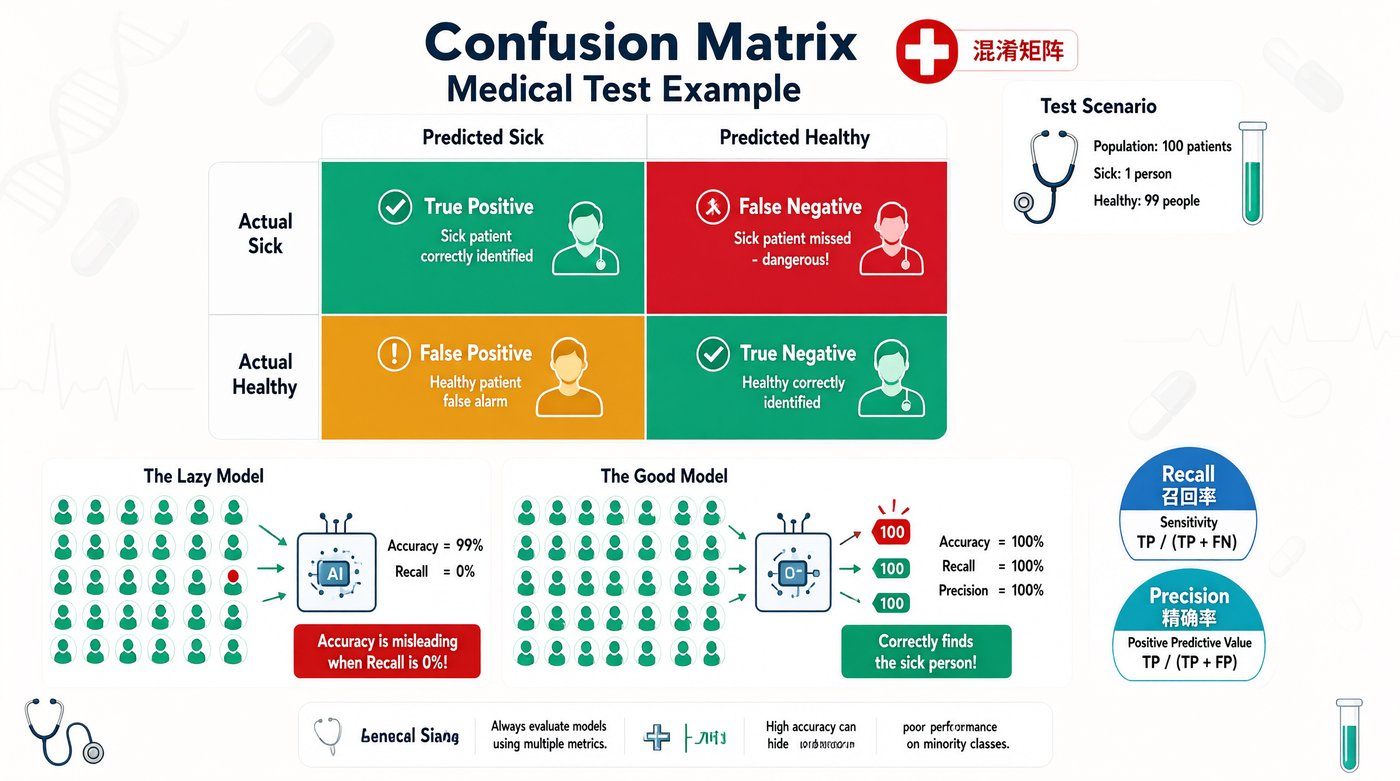
*Рис. 3. Матрица ошибок на примере медицинского теста. Почему Accuracy=99% может быть бесполезной.*



🦠 Сценарий: Редкая болезнь (1 из 100)
Accuracy (Точность): 99% (Выглядит отлично, но это ложь!)
Precision (Точность прогноза): 0%
Recall (Полнота):    0% (Модель не нашла ни одного больного!)
F1-score:           0%

📊 Матрица ошибок (Confusion Matrix):
[[TN, FP],
 [FN, TP]]
[[99  0]
 [ 1  0]]


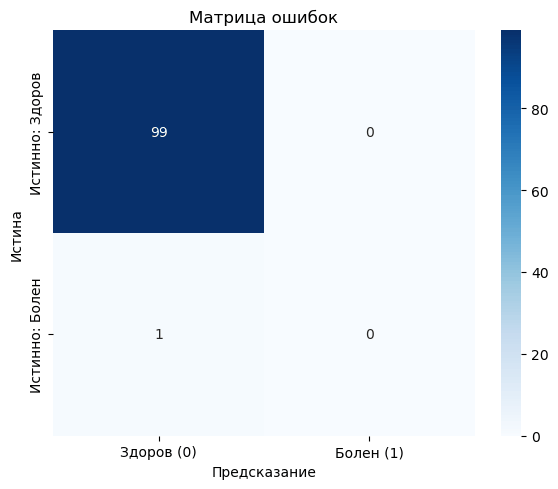

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 100 человек: 1 болен (1), 99 здоровы (0)
y_true = [1] + [0] * 99

# "Ленивая" модель: предсказывает, что все здоровы (0)
y_pred_lazy = [0] * 100

print("🦠 Сценарий: Редкая болезнь (1 из 100)")
print(f"Accuracy (Точность): {accuracy_score(y_true, y_pred_lazy):.0%} (Выглядит отлично, но это ложь!)")
print(f"Precision (Точность прогноза): {precision_score(y_true, y_pred_lazy, zero_division=0):.0%}")
print(f"Recall (Полнота):    {recall_score(y_true, y_pred_lazy):.0%} (Модель не нашла ни одного больного!)")
print(f"F1-score:           {f1_score(y_true, y_pred_lazy, zero_division=0):.0%}\n")

# Матрица ошибок
cm = confusion_matrix(y_true, y_pred_lazy)
print("📊 Матрица ошибок (Confusion Matrix):")
print("[[TN, FP],")
print(" [FN, TP]]")
print(cm)

# Визуализация матрицы ошибок
plt.figure(figsize=(6, 5))  # чуть больше
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Здоров (0)', 'Болен (1)'],
            yticklabels=['Истинно: Здоров', 'Истинно: Болен'])
plt.title('Матрица ошибок')
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.tight_layout()
plt.show()



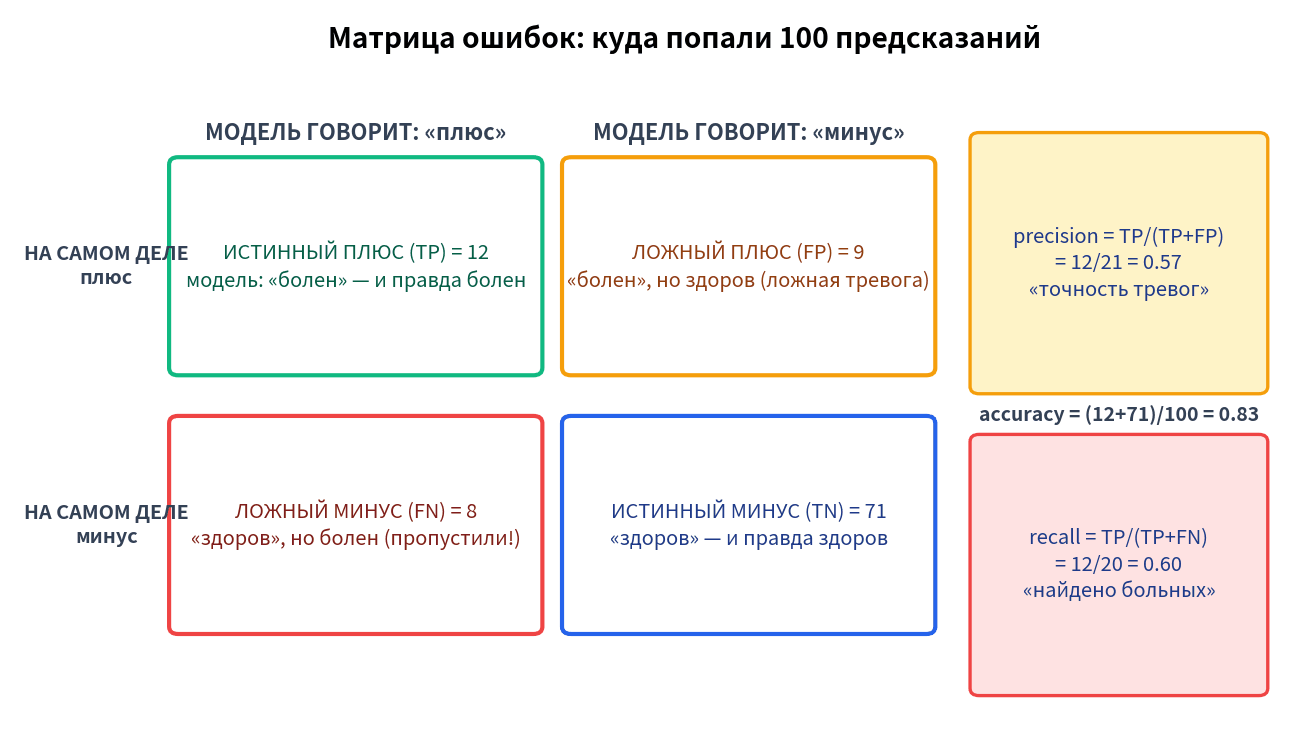

Четыре клетки с запоминающимися ролями: **TP** — попали, **TN** — правильно отмахнулись, **FP** — ложная тревога, **FN** — пропуск. Все метрики ниже — простые дроби из этих четырёх чисел.

### 5.2. Precision, Recall и их качели



### ✍️ Посчитаем метрики руками: фильтр спама

Пусть из 100 писем 20 — спам. Модель пометила как спам 18 писем, из которых 15 действительно спам (**TP = 15**), 3 — нормальные (**FP = 3**); ещё 5 спамных писем пропустила (**FN = 5**); верных пропусков **TN = 77**.

| Метрика | Расчёт | Значение | Смысл |
|---|---|---|---|
| accuracy | (15 + 77) / 100 | **0,92** | доля всех верных ответов |
| precision | 15 / (15 + 3) | **0,83** | из помеченных спамом 83 % — действительно спам |
| recall | 15 / (15 + 5) | **0,75** | поймали 75 % всего спама |
| F1 | 2·0,83·0,75 / (0,83 + 0,75) | **≈ 0,79** | баланс точности и полноты |

Такой расчёт занимает две минуты и мгновенно проясняет, **что именно «покупает» бизнес, меняя порог срабатывания**: поднять порог — меньше ложных тревог (precision ↑), но больше пропущенного спама (recall ↓).


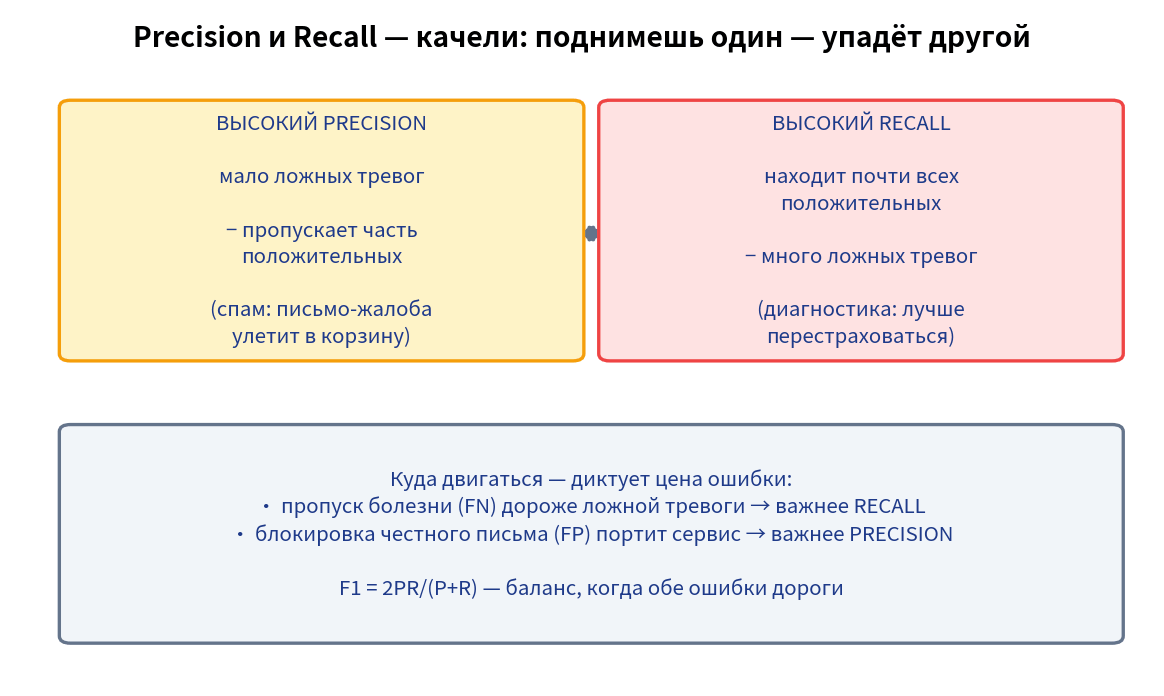

$$\text{precision} = \frac{TP}{TP+FP} \qquad \text{recall} = \frac{TP}{TP+FN}$$

Читаются просто: **precision** — «доля верных среди наших тревог», **recall** — «какую долю больных мы поймали». Двигая порог, мы перекачиваем ошибки из одной клетки в другую: низкий порог → много тревог → высокий recall, низкий precision; высокий порог — наоборот.

Сводный баланс — **F1-мера**:

$$F_1 = \frac{2 \, P \cdot R}{P + R}$$

F1 максимальна, когда P и R сбалансированы. Проверьте на матрице выше: P = 12/21 ≈ 0.57, R = 12/20 = 0.60, F1 ≈ 0.58.

### 5.3. Ловушка точности

Самая опасная ошибка новичка — мерить несбалансированные задачи одной accuracy:


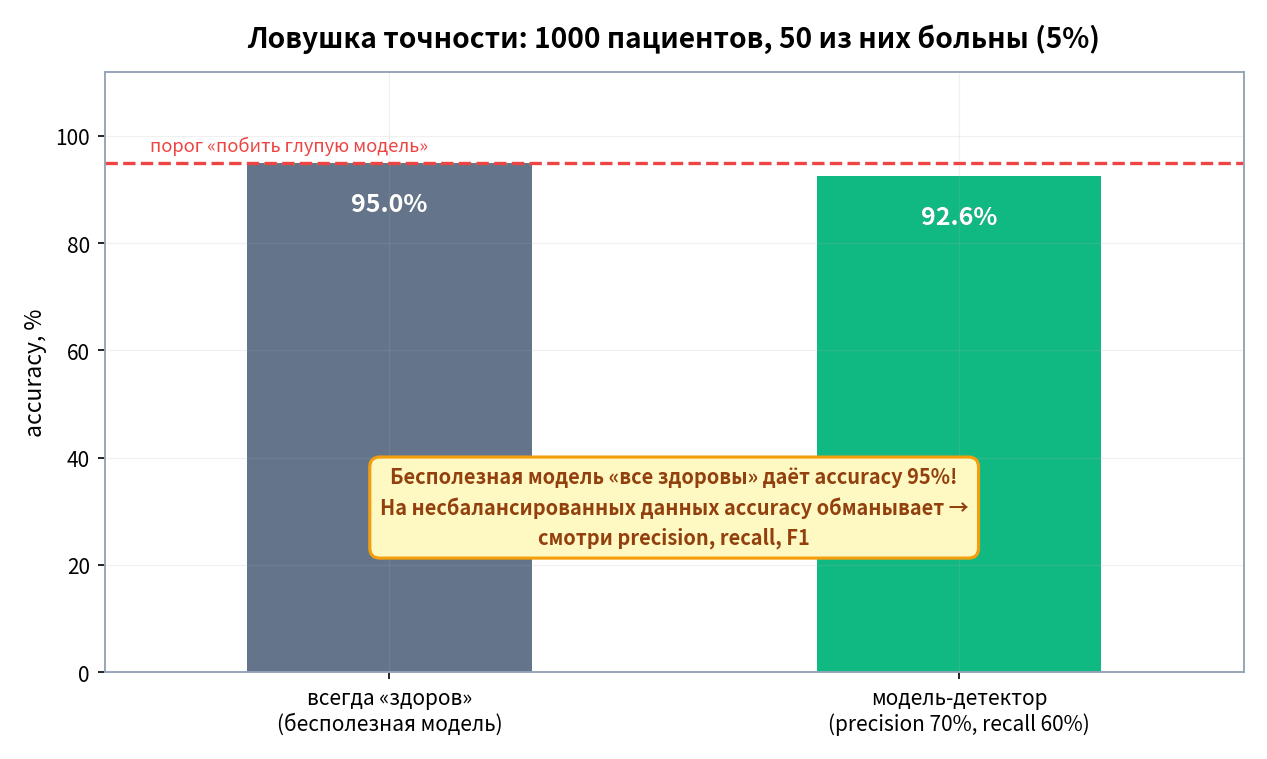

Модель «все здоровы» даёт 95% — и нулевую пользу: recall = 0, больных не нашли. Вывод: **при дисбалансе классов (спам ~1%, мошенничество ~0.2%, болезнь ~5%) сначала матрица ошибок, потом всё остальное.**

### 5.4. ROC и AUC: все пороги сразу


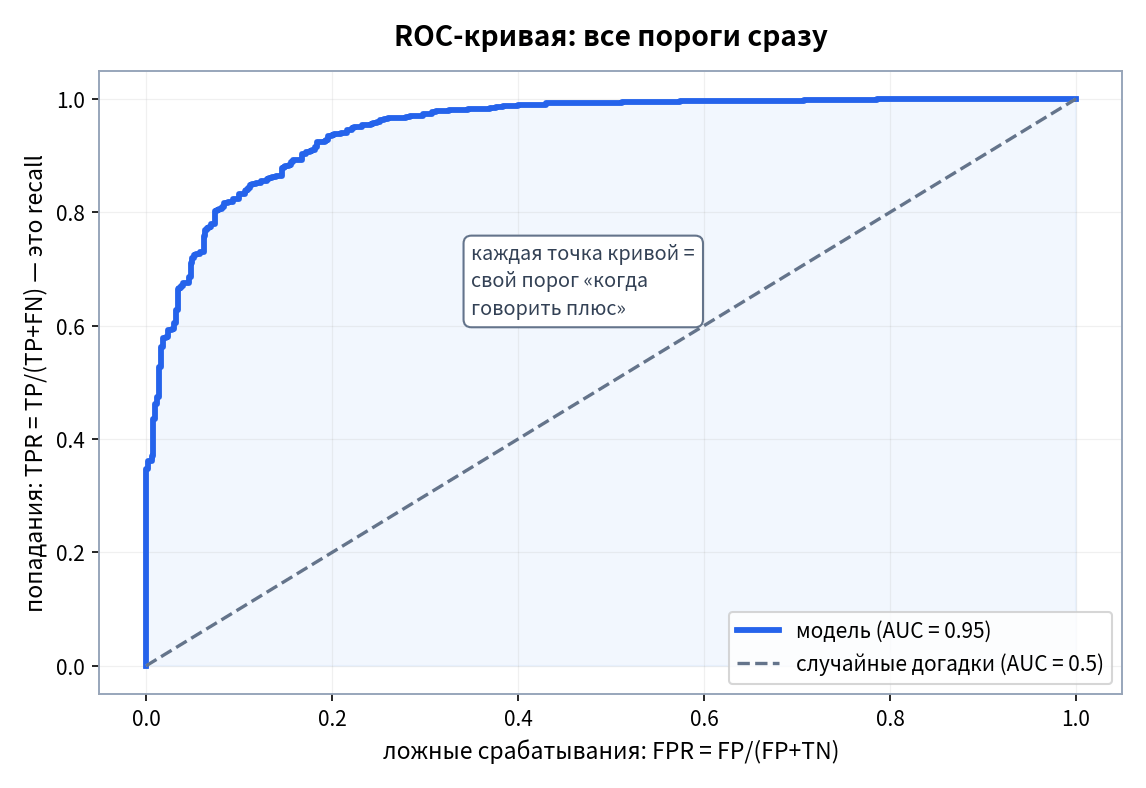

ROC-кривая рисует работу модели при **всех порогах сразу**: по оси X — доля ложных тревог (FPR), по оси Y — доля пойманных (TPR). Площадь под кривой (**AUC**) — единая оценка «отличает ли модель классы вообще»: 1.0 — идеал, 0.5 — уровень монетки, < 0.5 — перепутали классы. AUC удобен для сравнения моделей, но порог всё равно выбирать по цене ошибок.


In [ ]:
# Матрица ошибок и метрики на живых данных (ирисы, "versicolor" против остальных)
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

X, y = load_iris(return_X_y=True)
y_bin = (y == 1).astype(int)          # 1 = versicolor
X_tr, X_te, y_tr, y_te = train_test_split(X, y_bin, test_size=0.4, random_state=0)

m = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
pred = m.predict(X_te)
print(confusion_matrix(y_te, pred))   # [[TN FP] [FN TP]]
print(classification_report(y_te, pred, target_names=["не versicolor", "versicolor"]))

[[31  6]
 [13 10]]
               precision    recall  f1-score   support

не versicolor       0.70      0.84      0.77        37
   versicolor       0.62      0.43      0.51        23

     accuracy                           0.68        60
    macro avg       0.66      0.64      0.64        60
 weighted avg       0.67      0.68      0.67        60



## 6. Метрики регрессии и честный выбор модели
Когда мы предсказываем число (цену квартиры, температуру), Accuracy не работает.

### 6.1. Три метрики для «сколько?»

1. MAE (Mean Absolute Error, Средняя абсолютная ошибка)
Среднее значение модуля разницы между предсказанием и реальностью.
Пример: MAE = 50 000 юаней. Это значит, что в среднем модель ошибается в цене на 50 000 юаней.
Плюс: Измеряется в тех же единицах, что и целевая переменная (легко объяснить бизнесу).

2. R² (Коэффициент детерминации, R-квадрат)
Показывает, какую долю разброса данных объясняет наша модель.

R² = 1.0: Идеальное предсказание (все точки на линии).
R² = 0.0: Модель не лучше, чем просто предсказывать среднее значение всех данных.
R² < 0: Модель работает хуже, чем простое среднее (полный провал).
💡 Аналогия: Если R² = 0.85, это значит, что модель объясняет 85% причин изменения цены, а оставшиеся 15% — это случайный шум или факторы, которые мы не учли.

| Метрика | Формула | Когда смотреть |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y-\hat{y} \rvert$ | средняя ошибка «в рублях/баллах»; устойчива к выбросам |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y-\hat{y})^2}$ | штрафует большие промахи квадратом; если выбросы важны |
| **R²** | $1 - \frac{\sum (y-\hat{y})^2}{\sum (y-\bar{y})^2}$ | «какую долю разброса объяснила модель»; 1 — идеально, 0 — как среднее |

Чувствуете перекличку? MAE/RMSE — те же две философии, что и медиана/среднее из лекции 2.

### 6.2. Кросс-валидация: не подглядывая в тест


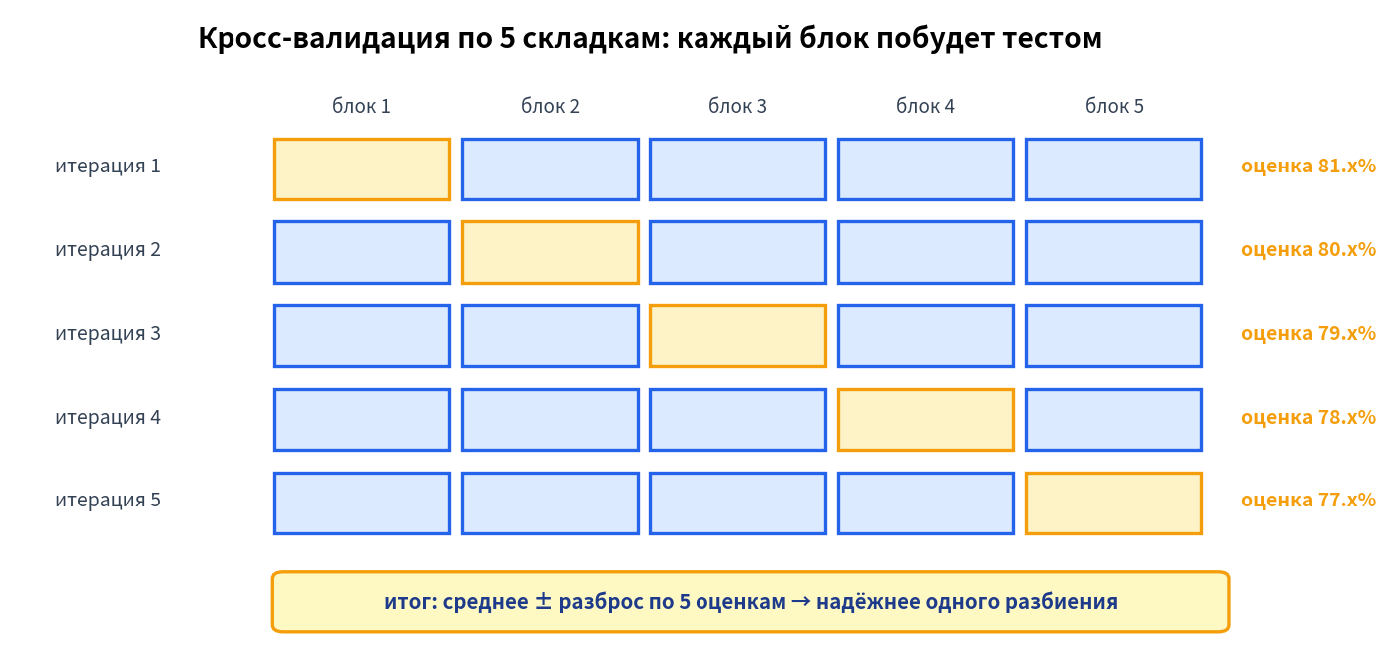

Один прогон на одном тесте — лотерея: повезёт/не повезёт с разбиением. Кросс-валидация (CV) делит **train** на 5 блоков и пять раз учит модель на четырёх, проверяя на пятом. Получаем пять оценок → среднее и разброс. Тест по-прежнему не тронут — он нужен один раз, в самом конце.


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# пайплайн = нормировка + модель: scaler учится ТОЛЬКО на обучающих складках (нет утечки!)
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))
scores = cross_val_score(pipe, X_tr, y_tr, cv=5, scoring="f1")
print(f"F1 по складкам: {np.round(scores, 3)}")
print(f"среднее {scores.mean():.3f} ± {scores.std():.3f}")

F1 по складкам: [0.909 1.    1.    0.889 0.889]
среднее 0.937 ± 0.052


Обратите внимание на **Pipeline**: нормировка внутри пайплайна учится заново на каждой складке — это и есть защита от утечки, о которой говорила лекция 3. Правило: *всё, что «узнаёт» данные, — внутрь пайплайна.*

**❓ Вопрос на подумать:** модель A даёт F1 0.80 ± 0.02, модель B — 0.83 ± 0.07. Какую возьмёте в продакшн и почему? *(Обычно A: стабильность важнее трети процента — B на некоторых разбиениях, видимо, проваливается.)*


---
## 🎬 Все видеоматериалы лекции 4
### 🇷🇺 РУС · русскоязычные видео (15)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [ML #29. Метрические методы: k ближайших соседей (kNN)](https://rutube.ru/video/40b38cd959a0b4627a67bfe0c96992df) | Rutube · SelfEdu | 11 мин | Л4 §2: kNN (П3 — классификация ирисов) | X |
| 2 | [[RUS Машинный Перевод] 9. Linear regression model part 1 — Модель линейной регрессии, часть 1](https://vkvideo.ru/video-227991006_456239093) | VK · Нга-ML | 10:26 | Л4 §3.1: модель линейной регрессии (мини-лекция) · [добавлено] | X |
| 3 | [[RUS Машинный Перевод] 15. Gradient descent — Градиентный спуск](https://vkvideo.ru/video-227991006_456239099) | VK · Нга-ML | 8:03 | П4 Часть А: как линейная модель подбирает коэффициенты · [добавлено] | X |
| 4 | [Лекция 2.1. Линейная регрессия](https://vkvideo.ru/video-155161349_456239169) | VK · DLS-1 | 19:41 | Л4 §3.1: линейная регрессия — цена квартиры за один умножитель · [добавлено] | X |
| 5 | [[RUS Машинный Перевод] 32. Logistic regression — Логистическая регрессия](https://vkvideo.ru/video-227991006_456239132) | VK · Нга-ML | 9:48 | Л4 §3.2: логистическая регрессия (мини-лекция) · [добавлено] | X |
| 6 | [ML #13. Логистическая регрессия](https://rutube.ru/video/7c5d902ce44b722b90c09e70a8f4e744) | Rutube · SelfEdu | 11 мин | Л4 §3.2: логистическая регрессия | X |
| 7 | [3. [RUS ИИ Перевод] K-means intuition — Интуиция алгоритма K-средних](https://vkvideo.ru/video-227991006_456239220) | VK · Нга-КЛ | 6:48 | Л4 §4.2 / П4 Часть Б: интуиция алгоритма K-средних · [добавлено] | X |
| 8 | [4. [RUS ИИ Перевод] K-means algorithm — Алгоритм K-средних](https://vkvideo.ru/video-227991006_456239221) | VK · Нга-КЛ | 9:49 | Л4 §4.2 / П4 Часть Б: алгоритм K-means · [добавлено] | X |
| 9 | [ML #33. Алгоритм кластеризации Ллойда (K-means)](https://rutube.ru/video/868c2995538b2a00d9a211ff46409adc) | Rutube · SelfEdu | 9 мин | Л4 §4.2 / П4: K-means (сегментация клиентов) | X |
| 10 | [ML #36. Логические методы классификации (деревья решений)](https://rutube.ru/video/ec2de8f32d3d03bd78f0871af1b26691) | Rutube · SelfEdu | 12 мин | Л4 §4.1: деревья решений | X |
| 11 | [Лекция. Решающие деревья](https://vkvideo.ru/video-155161349_456239192) | VK · DLS-1 | 31:12 | Л4 §4.1: дерево решений — инструкция, которую можно распечатать · [добавлено] | X |
| 12 | [Метрики машинного обучения](https://vkvideo.ru/video-155161349_456239195) | VK · DLS-1 | 10:04 | Л4 §5: матрица ошибок, accuracy, precision/recall · [добавлено] | X |
| 13 | [ML #23. Показатели precision и recall. F-мера](https://rutube.ru/video/61803ecd8bf8b94508cfa153f0524b93) | Rutube · SelfEdu | 14 мин | Л4 §5.2: метрики на несбалансированных данных | X |
| 14 | [ML #22. Вероятностная оценка качества моделей](https://rutube.ru/video/aa9e8e56d79db43dd6371ad5579820a2) | Rutube · SelfEdu | 9 мин | Л4 §5: доверие к метрикам | X |
| 15 | [36. [RUS ИИ Перевод] Diagnosing bias and variance — Диагностика смещения и разброса](https://vkvideo.ru/video-227991006_456239342) | VK · Нга-НС | 11:05 | П4: Bias / Variance и как помогает регуляризация · [добавлено] | X |


### 🇨🇳 中文 · китайскоязычные видео (20)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Введение в задачи классификации](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=8)<br>· ориг.: *3-1 分类问题介绍* | Bilibili · 清华AI | 16 мин | Л4 §1–2: постановка классификации | ✓ |
| 2 | [K-means, kNN и Mean-Shift](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=16)<br>· ориг.: *4-2 Kmeans-KNN-Meanshift* | Bilibili · 清华AI | 19 мин | Л4 §4: обзор семейства алгоритмов | ✓ |
| 3 | [Линейная регрессия](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=6)<br>· ориг.: *2-2 线性回归* | Bilibili · 清华AI | 25 мин | Л4 §2: линейная регрессия с нуля | ✓ |
| 4 | [Функции потерь](https://www.bilibili.com/video/BV1EY6FBwE8P?p=25)<br>· ориг.: *25.2-损失函数-* | Bilibili · 李沐 | 6 мин | Л4 §2: функции потерь (MSE и др.) | ✓ |
| 5 | [Линейная регрессия](https://www.bilibili.com/video/BV1EY6FBwE8P?p=19)<br>· ориг.: *19.1-线性回归* | Bilibili · 李沐 | 14 мин | Л4 §3.1: функция потерь и оптимизация | ✓ |
| 6 | [Базовые алгоритмы оптимизации (SGD)](https://www.bilibili.com/video/BV1EY6FBwE8P?p=20)<br>· ориг.: *20.2-基础优化算* | Bilibili · 李沐 | 8 мин | Л4: как градиентный спуск учится | ✓ |
| 7 | [Практика: однофакторная линейная регрессия](https://www.bilibili.com/video/BV1ctQzYUEbz?p=9)<br>· ориг.: *8. 单因子线性回归实战* | Bilibili · 清华36 | 17:19 | Л4 §3.1 · П4 часть А: линейная регрессия в коде · [добавлено] | ✓ |
| 8 | [Логистическая регрессия (часть 1)](https://www.bilibili.com/video/BV1ctQzYUEbz?p=11)<br>· ориг.: *10. 逻辑回归（1）* | Bilibili · 清华36 | 14 мин | Л4 §3.2: сигмоида и граница решений | ✓ |
| 9 | [Деревья решений (часть 1)](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=21)<br>· ориг.: *5-1 决策树（1）* | Bilibili · 清华AI | 13 мин | Л4 §4: деревья решений | ✓ |
| 10 | [Практика: дерево решений для банковских кредитов](https://www.bilibili.com/video/BV1Bw4B6zERQ?p=14)<br>· ориг.: *14.4-决策树实现银行贷款分类实战* | Bilibili · 10算法 | 19:22 | Л4 §4.1 · П3: классификация (кейс кредитов) · [добавлено] | ✓ |
| 11 | [Практика: классификация ирисов случайным лесом](https://www.bilibili.com/video/BV1Bw4B6zERQ?p=16)<br>· ориг.: *16.6-随机森林的鸢尾花分类实战* | Bilibili · 10算法 | 19:09 | П3, задание 1: замена kNN на RandomForestClassifier · [добавлено] | ✓ |
| 12 | [Принцип алгоритма K-means](https://www.bilibili.com/video/BV1Bw4B6zERQ?p=17)<br>· ориг.: *17.7- K-means聚类算法原理* | Bilibili · 10算法 | 11 мин | Л4 §4.2: кластеризация | ✓ |
| 13 | [Практика: код кластеризации k-means](https://www.bilibili.com/video/BV1Bw4B6zERQ?p=19)<br>· ориг.: *19.9-K-means聚类算法代码实战* | Bilibili · 10算法 | 15:11 | Л4 §4.2 · П4 часть Б: k-means в коде · [добавлено] | ✓ |
| 14 | [Метрики оценки кластеризации k-means](https://www.bilibili.com/video/BV1Bw4B6zERQ?p=18)<br>· ориг.: *18.8-K-means聚类算法的评估指标* | Bilibili · 10算法 | 8:33 | П4: выбор K — inertia и метод локтя · [добавлено] | ✓ |
| 15 | [Разделение данных и матрица ошибок](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=30)<br>· ориг.: *6-2 数据分离与混淆矩阵* | Bilibili · 清华AI | 21 мин | Л4 §5: выборки и confusion matrix | ✓ |
| 16 | [Матрица ошибок (confusion matrix)](https://www.bilibili.com/video/BV1BYe4z5E9z?p=52)<br>· ориг.: *052_核心原理_分类评价指标_混淆矩阵* | Bilibili · 尚硅谷 | 17 мин | Л4 §5.1: TP/FP/FN/TN | ✓ |
| 17 | [Accuracy, precision, recall и F1](https://www.bilibili.com/video/BV1BYe4z5E9z?p=53)<br>· ориг.: *053_…_准确率、精确率、召回率和F1* | Bilibili · 尚硅谷 | 18 мин | Л4 §5.2: главные метрики | ✓ |
| 18 | [ROC и AUC — максимально подробное и наглядное объяснение](https://www.bilibili.com/video/BV1CT4114799)<br>· ориг.: *ROC和AUC超详细生动讲解！* | Bilibili · 科技猎手2023 | 9:07 | Л4 §5.4: ROC-кривая и AUC с числовым примером | ✓ |
| 19 | [Переобучение и недообучение](https://www.bilibili.com/video/BV1ug4y1t7Ty?p=29)<br>· ориг.: *6-1 过拟合与欠拟合* | Bilibili · 清华AI | 18 мин | Л3 §5: диагностика пере/недообучения | ✓ |
| 20 | [Практика Kaggle: прогноз цен на жильё](https://www.bilibili.com/video/BV1EY6FBwE8P?p=50)<br>· ориг.: *50.1-实战 Kaggle 比赛：预测房价* | Bilibili · 李沐 | 14 мин | П4: полный цикл регрессии на реальных данных | ✓ |



### 🇬🇧 EN · англоязычные видео (13)
| № | Видео | Источник | Длит. | Раздел лекции | Доступность |
|---|-------|----------|-------|----------------|-------------|
| 1 | [Модель линейной регрессии](https://www.bilibili.com/video/BV1owrpYKEtP?p=6)<br>· ориг.: *6.线性回归模型 (речь — английская)* | Bilibili · 吴恩达 (NG, 2025) | 16:41 | Л4 §3.1: линейная регрессия — цена квартиры за один умножитель · [добавлено] | ✓ |
| 2 | [Andrew Ng: Функция потерь и её интуиция](https://www.bilibili.com/video/BV1owrpYKEtP?p=7)<br>· ориг.: *7.成本函数及其直觉 (речь — английская)* | Bilibili · 吴恩达 | 23 мин | Л4 §3: что минимизирует модель | ✓ |
| 3 | [Логистическая регрессия](https://www.bilibili.com/video/BV1owrpYKEtP?p=27)<br>· ориг.: *27.逻辑回归 (речь — английская)* | Bilibili · 吴恩达 (NG, 2025) | 9:49 | Л4 §3.2: логистическая регрессия — та же линия, но вероятность | ✓ |
| 4 | [StatQuest: логистическая регрессия — основные идеи](https://www.bilibili.com/video/BV1Q2QDYNEBN)<br>· ориг.: *【官方双语】一个视频带你看懂逻辑回归！* | Bilibili · StatQuest | 8 мин | Л4 §3.2: логистическая регрессия и сигмоида | ✓ |
| 5 | [StatQuest: кросс-энтропия (перекрёстная потеря)](https://www.bilibili.com/video/BV1BA4m1c7bB)<br>· ориг.: *【官方双语】一个视频理解交叉熵 Cross Entropy* | Bilibili · StatQuest | 9 мин | Л4 §3.2: функция потерь классификации | ✓ |
| 6 | [StatQuest: матрица ошибок (confusion matrix)](https://www.bilibili.com/video/BV1nC411H7wZ)<br>· ориг.: *【官方双语】一个视频理解混淆矩阵！confusion matrix* | Bilibili · StatQuest | 7 мин | Л4 §5.1: матрица ошибок | ✓ |
| 7 | [Andrew Ng: Метрики на несбалансированных данных](https://www.bilibili.com/video/BV1owrpYKEtP?p=85)<br>· ориг.: *85.倾斜数据集的错误指标 (речь — английская)* | Bilibili · 吴恩达 | 11 мин | Л4 §5.3: ловушка точности | ✓ |
| 8 | [Andrew Ng: Компромисс precision/recall](https://www.bilibili.com/video/BV1owrpYKEtP?p=86)<br>· ориг.: *86.精确率与召回率的权衡 (речь — английская)* | Bilibili · 吴恩达 | 11 мин | Л4 §5.2: баланс метрик | ✓ |
| 9 | [StatQuest: чувствительность и специфичность](https://www.bilibili.com/video/BV1Yr421E7CN)<br>· ориг.: *【官方双语】敏感性、特异性，详细解释！* | Bilibili · StatQuest | 11 мин | Л4 §5: метрики классификации | ✓ |
| 10 | [StatQuest: ROC и AUC — подробное объяснение](https://www.bilibili.com/video/BV1Fw4m1i72L)<br>· ориг.: *【官方双语】ROC & AUC 详细解释！* | Bilibili · StatQuest | 16 мин | Л4 §5.4: ROC-кривая и AUC | ✓ |
| 11 | [StatQuest: кросс-валидация за 6 минут](https://www.bilibili.com/video/BV1bx421k7bw)<br>· ориг.: *【官方双语】一个视频带你理解交叉验证* | Bilibili · StatQuest | 6 мин | Л4 §6: train/test и кросс-валидация | ✓ |
| 12 | [StatQuest: PCA (метод главных компонент)](https://www.bilibili.com/video/BV1dqikY5EBi)<br>· ориг.: *【官方双语】一个视频带你理解PCA（主成分分析）！* | Bilibili · StatQuest | 21 мин | Л4 Доп.: снижение размерности данных | ✓ |
| 13 | [吴恩达《机器学习》（中英字幕）](https://www.bilibili.com/video/BV164411b7dx) | Bilibili · 吴恩达 ML (2020) | курс · 112 эп., 19 ч 24 мин, 5,2 млн просм. | Л3+: полный курс Эндрю Нга · [добавлено] | ✓ |


---
## ❓ Мини-тест

1. **Какая задача решает вопрос «Сколько будет стоить дом?»?**
   <details><summary>Ответ</summary>Регрессия.</details>
2. **Что делает алгоритм kNN, если k=1?**
   <details><summary>Ответ</summary>Присваивает класс самого близкого соседа.</details>
3. **Нужны ли нам правильные ответы (метки) для кластеризации?**
   <details><summary>Ответ</summary>Нет, это обучение без учителя.</details>
4. **Когда метрика Accuracy (точность) обманывает?**
   <details>
   <summary>Показать ответ</summary>
   Когда классы несбалансированы (например, 99 здоровых и 1 больной). Модель может просто всегда предсказывать большинство и получить высокий accuracy, но быть бесполезной.
   </details>

5. **Что означает R² = 0.85?**
   <details>
   <summary>Показать ответ</summary>
   Модель объясняет 85% разброса (вариативности) целевой переменной. Это высокий показатель качества для регрессии.
   </details>

#### Контрольные вопросы

Нажмите на вопрос, чтобы раскрыть образец ответа.

**1. Какая китайская поговорка описывает метод k ближайших соседей? Воспроизведите её и объясните связь с алгоритмом.**
<details>
<summary>Показать ответ</summary>
<b>近朱者赤，近墨者黑</b> — «с красным станешь красным, с чёрным — чёрным». Это kNN в чистом виде: <b>класс объекта определяется его окружением</b> — голосованием k ближайших соседей.
</details>

**2. Что происходит при слишком маленьком и слишком большом k? Почему перед kNN признаки обязательно нормализуют?**
<details>
<summary>Показать ответ</summary>
Малое k: граница обвивает каждую точку, включая шумные → <b>переобучение</b>. Большое k: граница гладкая, но детали размываются → <b>недообучение</b>. Нормализация обязательна, потому что расстояние определяется признаком с самым большим масштабом: «доход в тысячах» задавит «рост в метрах» (пример из лекции 2).
</details>

**3. Почему дерево решений называют «объяснимым» алгоритмом? Какая опасность у одиночного дерева и как её лечат «леса»?**
<details>
<summary>Показать ответ</summary>
Дерево — печатная цепочка правил «если — то»: каждый лист можно показать заказчику, это самая интерпретируемая модель. Опасность: без ограничения глубины дерево <b>запоминает всю таблицу</b> (глубина 10+ — переобучение). «Леса» (случайный лес, бустинг) усредняют мнение сотен деревьев, обученных на разных подвыборках, — шум взаимно гасится.
</details>

**4. Опишите шаги алгоритма k-means и назовите два его ограничения.**
<details>
<summary>Показать ответ</summary>
Выбрать k → случайно расставить центры → приписать каждую точку ближайшему центру → пересчитать центры как средние своих групп → повторять шаги 3–4 до остановки. Ограничения: <b>k задаётся заранее</b> (метод локтя); любит «круглые» кластеры близкого размера (кольца разбивает плохо); результат зависит от стартовых центров → `n_init=10`.
</details>

**5. Почему kNN медленно отвечает на новых данных, хотя «не учится»? Где хранится вся информация о данных?**
<details>
<summary>Показать ответ</summary>
Обучение kNN «ленивое»: он просто <b>запоминает всю обучающую таблицу</b> — вся информация хранится в памяти (train-выборке), никаких весов не вычисляется. А на новом объекте надо посчитать расстояния до <b>всех</b> примеров — на больших данных это секунды на каждый запрос.
</details>

**6. k-means: что именно минимизирует алгоритм? Почему результат меняется между запусками?**
<details>
<summary>Показать ответ</summary>
Минимизирует <b>инерцию</b> — сумму квадратов расстояний от точек до их центров. Стартовые центры выбираются случайно, поэтому финальное разбиение может отличаться между запусками — лечится несколькими запусками (`n_init=10`) с выбором лучшего.
</details>

**7. Спам-фильтр с precision 0.45: много ли «нормальных писем» в корзине? Какая метрика важнее для почты?**
<details>
<summary>Показать ответ</summary>
Много: из 100 писем в корзине только 45 действительно спам, <b>55 — ложные тревоги</b>, то есть почти половина нормальных писем потеряна. Для почты важнее <b>precision</b>: важно не потерять важное письмо (пропущенный спам просто останется во входящих), поэтому порог срабатывания ставят высокий.
</details>

**8. Больница: как изменить порог логистической регрессии, чтобы поднять recall? Что при этом станет с precision?**
<details>
<summary>Показать ответ</summary>
<b>Снизить порог</b> (например, с 0,5 до 0,3): модель станет называть «больными» больше пациентов — найдёт больше реальных больных (recall ↑), но и ложных тревог станет больше (precision ↓). В медицине это правильный компромисс: пропустить больного дороже лишнего обследования.
</details>


## 📚 Глоссарий Лекции 4 (词汇表)

Алгоритмы и метрики качества (термины обучения — в Лекции 3).

| Термин (рус) | English | 中文 | Пояснение |
|--------------|---------|------|-----------|
| kNN | k-Nearest Neighbors | 最近邻算法 | Ленивый классификатор: голос k ближайших соседей; требует нормировки. |
| Линейная регрессия | Linear regression | 线性回归 | Модель y = w·x + b; минимизирует MSE; интерпретируема. |
| Логистическая регрессия | Logistic regression | 逻辑回归 | Линейная модель + сигмоида; даёт вероятность класса. |
| Дерево решений | Decision tree | 决策树 | Условия «если-то», разбивающие пространство признаков. |
| k-means | k-means | 均值聚类 | Итеративная кластеризация: точки к ближайшему центру, центр = среднее. |
| Гиперпараметр | Hyperparameter | 超参数 | Параметр, задаваемый до обучения (k, depth, lr); не учится из данных. |
| Регуляризация | Regularization | 正则化 | Штраф за сложность модели; защита от переобучения (L1, L2). |
| Матрица ошибок | Confusion matrix | 混淆矩阵 | Таблица «предсказано vs истинный»; показывает структуру ошибок. |
| Accuracy | Accuracy | 准确率 | Доля верных предсказаний; лжёт при дисбалансе классов. |
| Precision | Precision | 精确率 | TP/(TP+FP); какая доля предсказанных позитивов — истинные. |
| Recall | Recall | 召回率 | TP/(TP+FN); какая доля истинных позитивов найдена. |
| F1 | F1-score | F1分数 | Гармоническое среднее precision и recall; баланс. |
| ROC-кривая | ROC curve | ROC曲线 | График TPR vs FPR при разных порогах; чем выше, тем лучше. |
| AUC | Area Under ROC Curve | AUC | Площадь под ROC; 0.5 — случайно, 1.0 — идеально. |
| MSE | Mean Squared Error | 均方误差 | Средний квадрат ошибки; чувствительна к выбросам. |
| MAE | Mean Absolute Error | 平均绝对误差 | Среднее \|y−ŷ\|; устойчива к выбросам. |
| R² | Coefficient of determination | 决定系数 | Доля объяснённой дисперсии; 1 — идеально, 0 — не лучше среднего. |
| Кросс-валидация | Cross-validation | 交叉验证 | k-fold: данные делят на k частей, поочерёдно — test. |
| Базовая линия | Baseline | 基线 | Простейшая модель для сравнения; ML-проект должен её превзойти. |


## 🎓 Итоги Лекции 4

Лекция обозрела пять классических алгоритмов (kNN, линейная/логистическая регрессия, деревья, k-means) и метрики оценки (матрица ошибок, precision/recall/F1, ROC/AUC, MSE/MAE/R²), а также идею кросс-валидации для честного выбора модели.

### 🔑 Главные выводы

1. Классика (kNN, линейная/логистическая регрессия, деревья, k-means) — обязательные базовые линии для табличных задач.
2. kNN: ленивое обучение + голос соседей; $k$ и нормировка решают всё.
3. Линейная регрессия минимизирует MSE и объясняется ценами признаков; логистическая — вероятности через сигмоиду.
4. Деревья дают читаемые инструкции, но требуют ограничения глубины; k-means ищет группы без меток, $k$ подбирают «локтем».
5. Матрица ошибок — начало всех оценок. Precision против recall — качели, направление задаёт цена ошибки; F1 — баланс; при дисбалансе accuracy лжёт.
6. ROC/AUC сравнивают модели по всем порогам сразу.
7. Регрессию меряют MAE/RMSE/R². Модели выбирают кросс-валидацией; тест вскрывают один раз.

### 📝 Домашнее задание

1. **Метрики руками.** По матрице [[71, 9], [8, 12]] посчитайте accuracy, precision, recall, F1 (калькулятор запрещён — только NumPy). Сверьте с `classification_report`.
2. **Качели на пороге.** Обучите логистическую регрессию на ирисах (versicolor vs остальные) и прогоните пороги 0.1 … 0.9: постройте таблицу «порог → precision, recall». Где точка баланса F1?
3. **Анализ ситуации:** Представьте, что вы строите модель для обнаружения мошеннических транзакций в банке (мошенничество бывает в 0.1% случаев). Какую метрику вы будете оптимизировать в первую очередь: Accuracy, Recall или Precision? Почему?

### 📅 Следующее занятие

**Лекция 5: От нейрона к нейронной сети**

**Практика 4: Прогноз цены жилья и кластеризация K-means**

---

<center><i>Преподаватель: _______________</i></center>
<center><i>Дата проведения: _______________</i></center>